# 02 · Results: nothing beats persistence

Reads only generated results files (`results/final/test_results.json`, `results/rolling/rolling_results.json`,
`results/summary/headline.json`). MASE = MAE / MAE(persistence) on the same test windows; below 1 is better than
persistence. Verdicts follow the Diebold–Mariano rule (see `docs/DETAILED_REPORT.md` §3). That rule was preregistered for the rolling-origin
experiment (4.1) but not for the Phase 3 main comparison, whose rules are in committed scripts (`docs/DETAILED_REPORT.md` §3.4).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load = lambda p: json.loads((ROOT / p).read_text())
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

In [2]:
head = load("results/summary/headline.json")
pd.DataFrame(head["experiments"]).T[["seeds", "configurations", "beat_persistence_absolute", "beat_persistence_squared",
                                     "lowest_mean_mase", "lowest_mean_mase_configuration"]]

,seeds,configurations,beat_persistence_absolute,beat_persistence_squared,lowest_mean_mase,lowest_mean_mase_configuration
phase3_main_split,3,72,0,0,0.966,global_h30 ensemble|selected
statistical_baselines,1,21,0,0,0.995,global_h7 ets
rolling_origin_pooled,1,36,0,0,0.998,global_h1 tft
chronos_zero_shot,3,12,0,0,1.031,sudan_h30 chronos-mini
fx_target,3,18,0,0,1.145,sudan_h7 ensemble (FX route)
acled_main_split,3,18,0,0,1.115,main lag3 tft h7 (with conflict)
acled_rolling_pooled,1,6,0,0,1.088,rolling lag2 tft h7 (with conflict)
regime_dummies,3,36,0,0,1.032,fold5 tft h1 (without regime dummies)
transfer,3,12,0,0,1.085,gru h30 (transfer)


## Phase 3: MinMax scaling vs the validation-selected condition

Seed-mean test MASE per model, log scale. The dashed line is persistence.

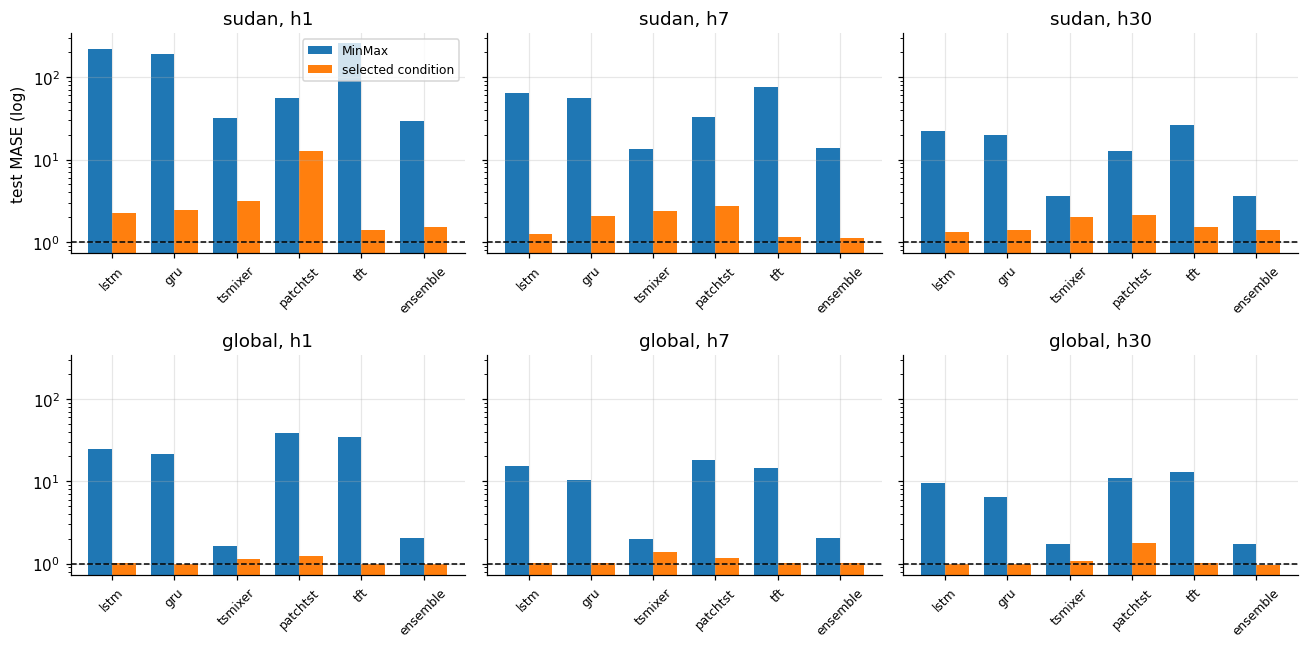

In [3]:
res = load("results/final/test_results.json")["results"]
models = ["lstm", "gru", "tsmixer", "patchtst", "tft", "ensemble"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, setting in zip(axes.flat, ["sudan_h1", "sudan_h7", "sudan_h30", "global_h1", "global_h7", "global_h30"]):
    cfg = res[setting]["configs"]
    x = np.arange(len(models))
    for j, cond in enumerate(["minmax", "selected"]):
        m = [np.mean([s["mase"] for s in cfg[f"{mod}|{cond}"]["seeds"]]) for mod in models]
        ax.bar(x + (j - 0.5) * 0.38, m, 0.38, label="MinMax" if cond == "minmax" else "selected condition")
    ax.axhline(1, color="k", ls="--", lw=1); ax.set_yscale("log"); ax.set_title(setting.replace("_", ", "))
    ax.set_xticks(x, models, rotation=45, fontsize=8)
axes[0, 0].set_ylabel("test MASE (log)"); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
rows = []
for setting, r in res.items():
    for key, c in r["configs"].items():
        if key.endswith("selected"):
            rows.append({"setting": setting, "model": key.split("|")[0], "condition": c["condition"],
                         "MASE mean": np.mean([s["mase"] for s in c["seeds"]]),
                         "verdict abs": c["verdict_absolute"], "verdict sq": c["verdict_squared"]})
pd.DataFrame(rows).pivot(index="model", columns="setting", values="MASE mean").round(3)

setting,global_h1,global_h30,global_h7,sudan_h1,sudan_h30,sudan_h7
model,,,,,,
ensemble,0.998,0.966,1.006,1.512,1.374,1.123
gru,1.001,1.001,1.007,2.440,1.409,2.054
lstm,1.003,0.999,1.012,2.228,1.324,1.259
patchtst,1.230,1.783,1.177,12.761,2.101,2.703
tft,0.999,1.005,1.014,1.392,1.522,1.134
tsmixer,1.126,1.083,1.365,3.089,2.021,2.375


## Sudan h = 30: validation does not carry over to test

Validation and test MASE per seed for the selected configurations. Points left of the vertical line beat
persistence on validation; none is below the horizontal line on test.

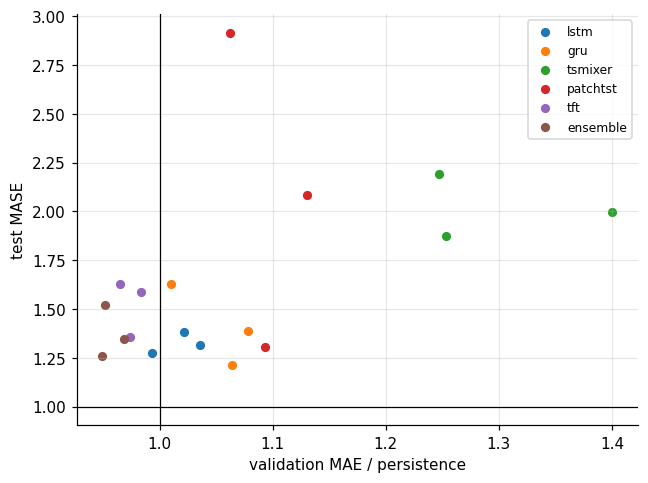

In [5]:
r = res["sudan_h30"]
fig, ax = plt.subplots(figsize=(6, 4.5))
for k, c in r["configs"].items():
    if not k.endswith("selected"):
        continue
    v = [s["val_mae"] / r["val_persistence_mae"] for s in c["seeds"]]
    t = [s["mase"] for s in c["seeds"]]
    ax.scatter(v, t, label=k.split("|")[0], s=25)
ax.axvline(1, color="k", lw=0.8); ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("validation MAE / persistence"); ax.set_ylabel("test MASE"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Rolling origin (5 folds, one seed): per-fold MASE

Folds overlap the Phase 3 validation and test periods (they are not untouched data).

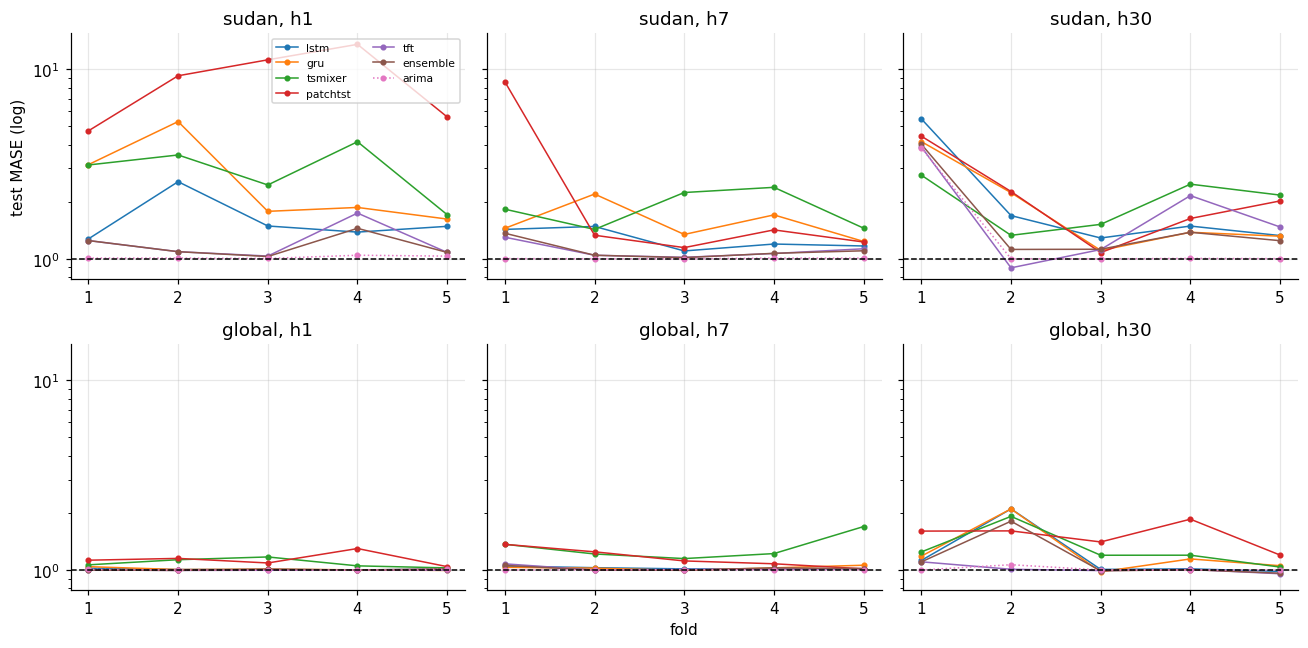

In [6]:
roll = load("results/rolling/rolling_results.json")["results"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, (setting, r) in zip(axes.flat, roll.items()):
    for m in ["lstm", "gru", "tsmixer", "patchtst", "tft", "ensemble", "arima"]:
        ax.plot([1, 2, 3, 4, 5], [r["folds"][str(k)]["scores"][m]["mase"] for k in range(1, 6)], marker="o", ms=3,
                lw=1, label=m, ls=":" if m == "arima" else "-")
    ax.axhline(1, color="k", ls="--", lw=1); ax.set_yscale("log"); ax.set_title(setting.replace("_", ", "))
    ax.set_xticks([1, 2, 3, 4, 5])
axes[0, 0].set_ylabel("test MASE (log)"); axes[1, 1].set_xlabel("fold"); axes[0, 0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()